# 10. Perfil por idade e sexo em anos epidêmicos e não epidêmicos (P4)

**Pergunta 4:** a distribuição dos casos por faixa etária e sexo muda entre anos epidêmicos e não epidêmicos?

| Entrada | Saída |
|---|---|
| `notificacao_dengue_ne`, `populacao_municipio_ano`, `municipio` (tratadas) | composição por idade e sexo nos dois grupos, por estado e ao longo do tempo; achados no fim |

**Método.** Ano epidêmico é definido por **estado-ano**: incidência de casos prováveis ≥ 300 por 100 mil (faixa alta,
decisão 11; mesma classificação do `07_incidencia`). Faixas etárias: 0–4, 5–9, 10–19, 20–39, 40–59, 60+.
Comparamos a **composição** dos casos (percentual em cada faixa). Incidência por idade exigiria a população por faixa
etária, que o banco ainda não tem. Com milhões de casos, qualquer diferença dá "significativa"; por isso olhamos o
tamanho do efeito (**V de Cramér**: perto de 0 = composições parecidas; 0,1 já é uma diferença visível) e as diferenças
em pontos percentuais (p.p.).

**Neste notebook**
1. Dados
2. Faixa etária: epidêmico × não epidêmico
3. O padrão se repete nos estados?
4. Sexo
5. Idade dos casos ao longo do tempo
6. Achados

In [1]:
import sys
from pathlib import Path
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.append(str(RAIZ / "src"))

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import eda

eda.estilo()

## 1. Dados

In [2]:
painel = eda.painel_municipio_ano()
uf_ano = painel.groupby(["uf", "ano"], observed=True)[["provaveis", "populacao"]].sum()
uf_ano["epidemico"] = eda.incidencia(uf_ano.provaveis, uf_ano.populacao) >= eda.LIMIAR_ALTA

perfil = eda.casos_idade_sexo()
perfil["epidemico"] = pd.MultiIndex.from_frame(perfil[["uf", "ano"]]).map(uf_ano.epidemico)
grupo = {False: "não epidêmico", True: "epidêmico"}
perfil["grupo"] = perfil.epidemico.map(grupo)
assert perfil.casos.sum() == uf_ano.provaveis.sum()

n_epi = int(uf_ano.epidemico.sum())
casos_epi = perfil.loc[perfil.epidemico, "casos"].sum()
print(f"Estado-anos epidêmicos: {n_epi} de {len(uf_ano)}; casos neles: {casos_epi:,} "
      f"({casos_epi / perfil.casos.sum():.0%} do total)")
print(f"Sem idade: {perfil.loc[perfil.faixa_etaria.isna(), 'casos'].sum():,} | "
      f"sem sexo: {perfil.loc[perfil.sexo.isna(), 'casos'].sum():,} (ficam fora só da parte que usa o campo)")

Estado-anos epidêmicos: 84 de 234; casos neles: 3,005,119 (72% do total)
Sem idade: 6,165 | sem sexo: 5,679 (ficam fora só da parte que usa o campo)


## 2. Faixa etária: epidêmico × não epidêmico

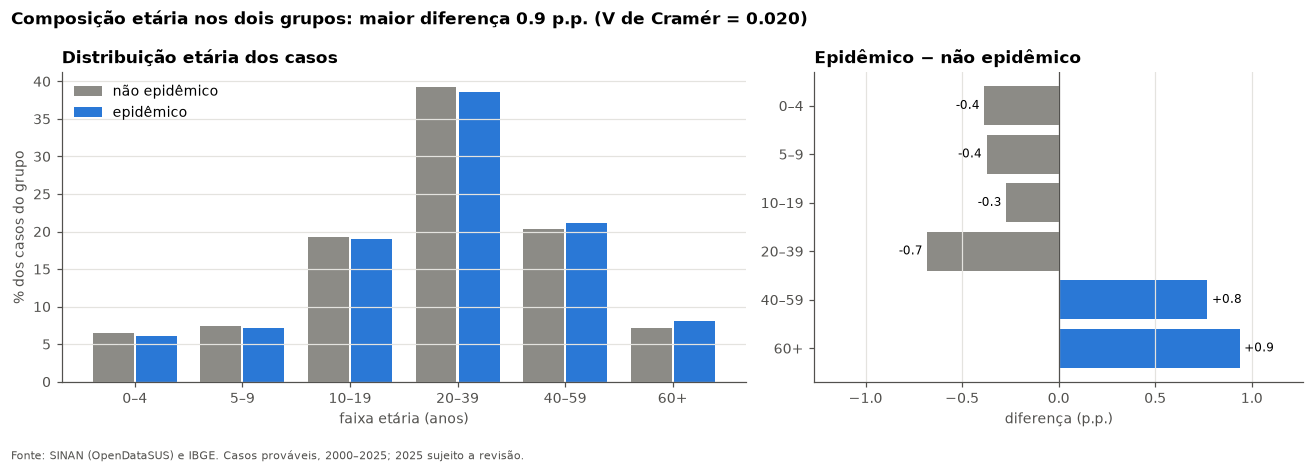

V de Cramér (idade × grupo) = 0.020


grupo,não epidêmico,epidêmico,diferença (p.p.)
faixa_etaria,,,
0–4,6.5,6.1,-0.4
5–9,7.5,7.1,-0.4
10–19,19.2,19.0,-0.3
20–39,39.2,38.6,-0.7
40–59,20.4,21.2,0.8
60+,7.1,8.1,0.9


In [3]:
tab = perfil.pivot_table(index="faixa_etaria", columns="grupo", values="casos", aggfunc="sum", observed=True)
tab = tab[["não epidêmico", "epidêmico"]]
pct = tab / tab.sum() * 100
dif = pct["epidêmico"] - pct["não epidêmico"]
v = eda.v_de_cramer(tab)

fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.arange(len(pct))
axs[0].bar(x - 0.2, pct["não epidêmico"], 0.38, color=eda.COR["referencia"], label="não epidêmico")
axs[0].bar(x + 0.2, pct["epidêmico"], 0.38, color=eda.COR["principal"], label="epidêmico")
axs[0].set_xticks(x, pct.index)
axs[0].set(xlabel="faixa etária (anos)", ylabel="% dos casos do grupo", title="Distribuição etária dos casos")
axs[0].legend(loc="upper left")
barras = axs[1].barh(dif.index.astype(str), dif, color=np.where(dif > 0, eda.COR["principal"], eda.COR["referencia"]))
axs[1].bar_label(barras, labels=[f"{d:+.1f}" for d in dif], padding=3, fontsize=8)
axs[1].set_xlim(-abs(dif).max() * 1.35, abs(dif).max() * 1.35)
axs[1].axvline(0, color=eda.COR["texto2"], lw=0.8)
axs[1].invert_yaxis()
axs[1].grid(axis="x", color=eda.COR["grade"])
axs[1].grid(axis="y", visible=False)
axs[1].set(xlabel="diferença (p.p.)", title="Epidêmico − não epidêmico")
fig.suptitle(f"Composição etária nos dois grupos: maior diferença {dif.abs().max():.1f} p.p. (V de Cramér = {v:.3f})", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
eda.nota(fig)
plt.show()

print(f"V de Cramér (idade × grupo) = {v:.3f}")
pct.assign(**{"diferença (p.p.)": dif}).round(1)

## 3. O padrão se repete nos estados?
Diferença (p.p.) entre epidêmico e não epidêmico em cada estado. Azul = faixa com peso maior nas epidemias; vermelho =
peso menor. Estados com poucos anos epidêmicos (MA tem 1, SE tem 3) têm comparação mais frágil.

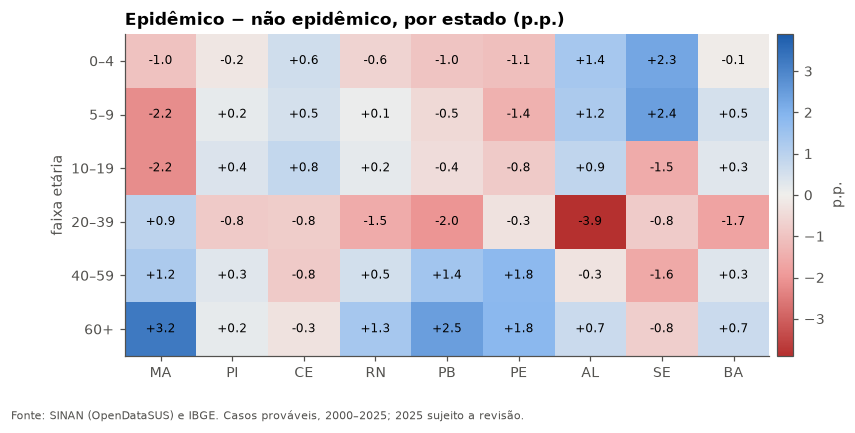

,MA,PI,CE,RN,PB,PE,AL,SE,BA
faixa_etaria,,,,,,,,,
0–4,-1.0,-0.2,0.6,-0.6,-1.0,-1.1,1.4,2.3,-0.1
5–9,-2.2,0.2,0.5,0.1,-0.5,-1.4,1.2,2.4,0.5
10–19,-2.2,0.4,0.8,0.2,-0.4,-0.8,0.9,-1.5,0.3
20–39,0.9,-0.8,-0.8,-1.5,-2.0,-0.3,-3.9,-0.8,-1.7
40–59,1.2,0.3,-0.8,0.5,1.4,1.8,-0.3,-1.6,0.3
60+,3.2,0.2,-0.3,1.3,2.5,1.8,0.7,-0.8,0.7


,anos epidêmicos,V de Cramér
MA,1,0.053
PI,8,0.011
CE,14,0.018
RN,16,0.020
PB,11,0.047
PE,8,0.049
AL,11,0.041
SE,3,0.064
BA,12,0.018


In [4]:
dif_uf = {}
for uf, d in perfil.groupby("uf", observed=True):
    t = d.pivot_table(index="faixa_etaria", columns="epidemico", values="casos", aggfunc="sum", observed=True)
    if {True, False} <= set(t.columns):
        p = t / t.sum() * 100
        dif_uf[uf] = p[True] - p[False]
dif_uf = pd.DataFrame(dif_uf)
lim = np.abs(dif_uf.to_numpy()).max()

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(dif_uf, cmap=eda.DIVERGENTE.reversed(), vmin=-lim, vmax=lim, aspect="auto")
for i in range(dif_uf.shape[0]):
    for j in range(dif_uf.shape[1]):
        ax.text(j, i, f"{dif_uf.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(dif_uf.shape[1]), dif_uf.columns)
ax.set_yticks(range(dif_uf.shape[0]), dif_uf.index)
ax.grid(False)
ax.set(ylabel="faixa etária", title="Epidêmico − não epidêmico, por estado (p.p.)")
fig.colorbar(im, ax=ax, label="p.p.", pad=0.01)
eda.nota(fig)
plt.show()

display(dif_uf.round(1))
anos_epi = uf_ano.epidemico.groupby("uf", observed=True).sum()
v_uf = {uf: eda.v_de_cramer(d.pivot_table(index="faixa_etaria", columns="epidemico", values="casos",
                                          aggfunc="sum", observed=True))
        for uf, d in perfil.groupby("uf", observed=True) if d.epidemico.nunique() == 2}
pd.DataFrame({"anos epidêmicos": anos_epi, "V de Cramér": pd.Series(v_uf)}).round(3)

## 4. Sexo
Percentual de mulheres entre os casos (sem os casos com sexo vazio), no total e por faixa etária.

sexo              F     M
grupo                    
não epidêmico  56.2  43.8
epidêmico      57.3  42.7
V de Cramér (sexo × grupo) = 0.010


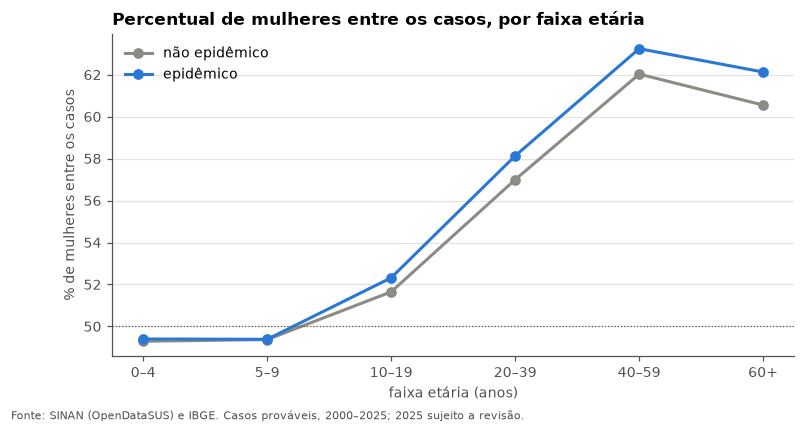

faixa_etaria,0–4,5–9,10–19,20–39,40–59,60+
grupo,,,,,,
não epidêmico,49.3,49.4,51.7,57.0,62.0,60.6
epidêmico,49.4,49.4,52.3,58.1,63.2,62.1


In [5]:
ds = perfil.dropna(subset=["sexo"])
ts = ds.pivot_table(index="grupo", columns="sexo", values="casos", aggfunc="sum").loc[["não epidêmico", "epidêmico"]]
print((ts.div(ts.sum(axis=1), axis=0) * 100).round(1).to_string())
print(f"V de Cramér (sexo × grupo) = {eda.v_de_cramer(ts):.3f}")

fem = (ds.assign(F=np.where(ds.sexo == "F", ds.casos, 0))
         .groupby(["faixa_etaria", "grupo"], observed=True)[["F", "casos"]].sum())
fem = (fem.F / fem.casos * 100).unstack("grupo")[["não epidêmico", "epidêmico"]]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(fem.index.astype(str), fem["não epidêmico"], marker="o", color=eda.COR["referencia"], label="não epidêmico")
ax.plot(fem.index.astype(str), fem["epidêmico"], marker="o", color=eda.COR["principal"], label="epidêmico")
ax.axhline(50, color=eda.COR["limiar"], lw=0.8, ls=":")
ax.set(xlabel="faixa etária (anos)", ylabel="% de mulheres entre os casos",
       title="Percentual de mulheres entre os casos, por faixa etária")
ax.legend(loc="upper left")
eda.nota(fig)
plt.show()
fem.round(1).T

## 5. Idade dos casos ao longo do tempo
Idade mediana dos casos prováveis do Nordeste por ano (calculada no banco). Faixas cinza = anos em que pelo menos 5
estados tiveram incidência alta.

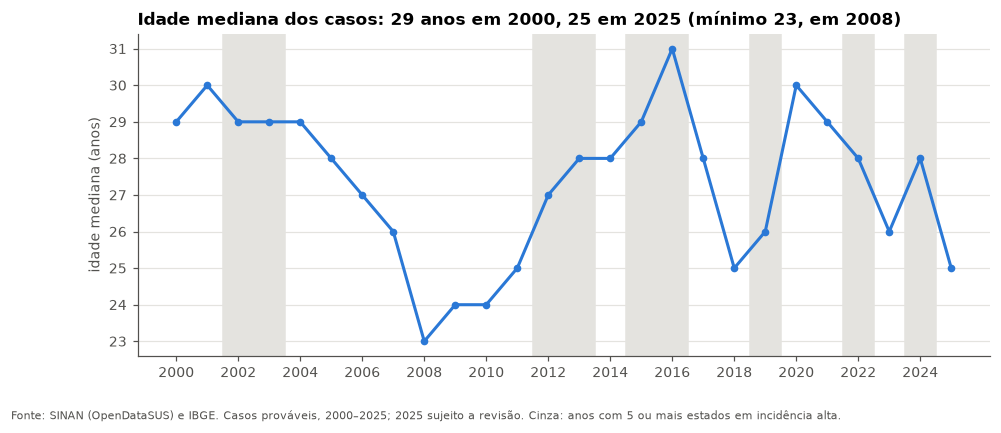

,mediana,pct_menor15,pct_60mais,estados em alta
ano,,,,
2000,29.0,15.8,7.1,3
2001,30.0,15.6,8.0,4
2002,29.0,17.3,6.9,5
2003,29.0,16.2,8.4,5
2004,29.0,16.7,7.5,0
2005,28.0,18.3,8.1,1
2006,27.0,21.8,6.8,1
2007,26.0,26.1,6.8,4
2008,23.0,31.7,5.5,4


In [6]:
idade = eda.consulta("""
    SELECT ano, percentile_cont(0.5) WITHIN GROUP (ORDER BY idade_anos) AS mediana,
           avg((idade_anos < 15)::int) * 100 AS pct_menor15, avg((idade_anos >= 60)::int) * 100 AS pct_60mais
    FROM notificacao_dengue_ne
    WHERE caso_provavel AND idade_anos IS NOT NULL AND ano BETWEEN 2000 AND 2025
    GROUP BY ano ORDER BY ano""").set_index("ano").astype(float)
n_alta = uf_ano.epidemico.groupby("ano").sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
for ano in n_alta.index[n_alta >= 5]:
    ax.axvspan(ano - 0.5, ano + 0.5, color=eda.COR["grade"], zorder=0)
ax.plot(idade.index, idade.mediana, marker="o", ms=4, color=eda.COR["principal"])
ax.set_xticks(idade.index[::2])
ax.set(ylabel="idade mediana (anos)",
       title=f"Idade mediana dos casos: {idade.mediana.iloc[0]:.0f} anos em 2000, {idade.mediana.iloc[-1]:.0f} em 2025 "
             f"(mínimo {idade.mediana.min():.0f}, em {idade.mediana.idxmin()})")
eda.nota(fig, eda.FONTE + " Cinza: anos com 5 ou mais estados em incidência alta.")
plt.show()
idade.assign(**{"estados em alta": n_alta}).round(1)

## 6. Achados
- **Peso das epidemias:** 84 dos 234 estado-anos foram epidêmicos e concentram 72% dos casos prováveis.
- **Idade quase não muda:** a composição etária é praticamente a mesma nos dois grupos (V de Cramér 0,020). A maior
  diferença é de 0,9 p.p.: nas epidemias, um pouco mais de casos com 40 anos ou mais e um pouco menos abaixo de 40.
- **Sem padrão comum entre estados:** V de 0,011 (PI) a 0,064 (SE). MA e PB têm mais idosos nas epidemias (+3,2 e +2,5
  p.p. em 60+); SE tem mais crianças (+2,3 e +2,4 p.p. em 0–4 e 5–9). MA (1 ano epidêmico) e SE (3) têm comparação frágil.
- **Sexo:** mulheres são 56% dos casos fora das epidemias e 57% nelas (V 0,010). A diferença está nos adultos:
  ~49% de mulheres até 9 anos e 57% a 63% a partir dos 20, nos dois grupos.
- **Idade ao longo do tempo:** a idade mediana varia mais entre anos do que entre epidêmico e não epidêmico: 29 anos em
  2000, mínimo de 23 em 2008 (32% dos casos com menos de 15 anos), máximo de 31 em 2016 e 25 em 2025.
- **Limite:** sem população por faixa etária, não dá para dizer em que idade o **risco** é maior, só como os casos se
  distribuem.